# Séance 3 · Rechercher dans les textes médicaux avec OpenSearch

M2 Data Science en santé, option Data, Université de Lille.

Ce notebook suit les parties du cours :

| Partie | Dans ce notebook |
|---|---|
| 01 · Moteurs plein texte | votre index inversé, en Python (exercice) |
| 02 · Indexer et interroger | créer l'index, indexer le corpus, **TP requêtes** (étapes 1 à 5) |
| 03 · Analyse et agrégations | comparer les analyseurs, analyseur français et synonymes, agrégations |
| 04 · Pertinence et sens | surbrillance, **négation avec EDS-NLP**, enrichir l'index pour une cohorte |

Les cellules marquées `# À COMPLÉTER` sont à écrire ; les autres s'exécutent telles quelles.
Le corpus `donnees/comptes_rendus.ndjson` est **entièrement fictif** : 600 comptes rendus, aucun patient réel.

Avant de commencer : OpenSearch doit tourner (voir le README). Exécutez les cellules dans l'ordre.

## Partie 01 · Votre index inversé (exercice, 6 min)

Le même exercice que la slide « Votre index inversé », en Python. Pas besoin d'OpenSearch pour cette partie :
seulement Python, sans aucun paquet.

In [1]:
PHRASES = {
    1: "Insuffisance cardiaque décompensée",
    2: "Pas d'insuffisance rénale",
    3: "Décompensation cardiaque aiguë",
}
MOTS_VIDES = {"pas", "de", "la", "le", "les", "du", "des", "un", "une"}

def decouper(texte):
    """Découpage naïf : minuscules, puis un mot à chaque espace, sans les mots vides."""
    return [mot for mot in texte.lower().split() if mot not in MOTS_VIDES]

for num, phrase in PHRASES.items():
    print(num, decouper(phrase))

1 ['insuffisance', 'cardiaque', 'décompensée']
2 ["d'insuffisance", 'rénale']
3 ['décompensation', 'cardiaque', 'aiguë']


Construisez l'index inversé : un dictionnaire qui associe à chaque mot l'ensemble des numéros de phrases où il apparaît.

In [2]:
# À COMPLÉTER : remplir index, de la forme {"cardiaque": {1, 3}, ...}
index = {}

for num, phrase in PHRASES.items():
    for mot in decouper(phrase):
        if mot not in index:
            index[mot] = set()
        index[mot].add(num)

for mot in sorted(index):
    print(f"{mot:16s}", sorted(index[mot]))

aiguë            [3]
cardiaque        [1, 3]
d'insuffisance   [2]
décompensation   [3]
décompensée      [1]
insuffisance     [1]
rénale           [2]


In [3]:
def chercher(mot):
    """Les phrases qui contiennent le mot, d'après l'index."""
    return sorted(index.get(mot.lower(), set()))

for mot in ["cardiaque", "décompensation", "insuffisance"]:
    print(f"{mot:16s} →", chercher(mot))

cardiaque        → [1, 3]
décompensation   → [3]
insuffisance     → [1]


**Questions** :
1. Pourquoi « décompensation » ne trouve-t-il pas la phrase 1, qui parle pourtant de la même chose ?
2. Pourquoi « insuffisance » ne trouve-t-il pas la phrase 2 ? Regardez comment `decouper` a traité « d'insuffisance ».

Ces deux défauts sont exactement ce que corrige l'analyse du texte de la partie 03 (racine, élision).
Dans la suite, OpenSearch construit cet index pour vous, sur 600 comptes rendus.

1. La phrase 1 contient "décompensée". L'index enregistre chaque mot tel qu'il apparaît après le découpage, sans le rameneer à une racine commune. Il stocke donc "décompensée" et "décompensation"sous deux clés différentes. La recherche "décompensation" renvoie seulement la phrase 3.

2. La fonction .split() découpe la phrase aux espaces. Comme il n'y a pas d'espace après l'apostrophe, d'insuffisance reste un seul mot dans l'index. La recherche "insuffisance" renvoie donc seulement la phrase 1, où le mot apparaît. 


In [ ]:
%pip install pandas opensearch-py


Note: you may need to restart the kernel to use updated packages.


c:\Users\methu\AppData\Local\spyder-6\python.exe: No module named pip


In [ ]:
#%pip install opensearch-py

  Using cached opensearch_py-3.2.0-py3-none-any.whl.metadata (7.2 kB)
  Using cached Events-0.5-py3-none-any.whl.metadata (3.9 kB)
  Using cached opensearch_protobufs-1.2.0-py3-none-any.whl.metadata (677 bytes)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached grpcio-1.85.3-cp311-cp311-win_amd64.whl.metadata (3.9 kB)
Using cached opensearch_py-3.2.0-py3-none-any.whl (387 kB)
Using cached opensearch_protobufs-1.2.0-py3-none-any.whl (54 kB)
Using cached Events-0.5-py3-none-any.whl (6.8 kB)
Using cached grpcio-1.85.3-cp311-cp311-win_amd64.whl (5.6 MB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import sys
print(sys.executable)

c:\Users\methu\AppData\Local\spyder-6\python.exe


In [1]:
# Connexion à OpenSearch (sécurité désactivée : TP uniquement)
import os, json
import pandas as pd
from opensearchpy import OpenSearch, helpers

HOTE = os.environ.get("OPENSEARCH_HOST", "localhost")
client = OpenSearch(hosts=[{"host": HOTE, "port": 9200}], use_ssl=False, timeout=60)
info = client.info()
print("OpenSearch", info["version"]["number"], "répond sur", HOTE)

OpenSearch 3.8.0 répond sur localhost


## Partie 02 · Indexer et interroger

### Le corpus

Chaque ligne du fichier est un compte rendu : identifiant, patient, titre, service, date, âge, sexe et texte libre.

In [2]:
corpus = pd.read_json("donnees/comptes_rendus.ndjson", lines=True, dtype={"date_creation": str})
print(len(corpus), "comptes rendus,", corpus["patient_id"].nunique(), "patients")
print(corpus["service"].value_counts().to_string())
corpus.head(3)

600 comptes rendus, 215 patients
service
Cardiologie         146
Endocrinologie       96
Urgences             89
Néphrologie          72
Pneumologie          66
Neurologie           61
Gériatrie            42
Médecine interne     28


,id,patient_id,titre,service,date_creation,age,sexe,contenu
0,CR0001,P0076,Compte rendu de passage aux urgences,Urgences,2025-10-13,89,M,Motif : Bilan annuel du diabète. Patient connu...
1,CR0002,P0210,Compte rendu de consultation,Cardiologie,2024-12-25,31,F,Motif : Palpitations depuis 48 heures. Patient...
2,CR0003,P0175,Lettre de sortie,Médecine interne,2024-08-05,32,M,"Motif : Bilan d'obésité, IMC à 38 kg/m². Obési..."


In [5]:
print(corpus.loc[0, "contenu"])

Motif : Bilan annuel du diabète. Patient connu pour un diabète sucré de type 2. Pas d'AVC ischémique. Antécédents : HTA. Possible dyslipidémie, à confirmer. Examen : tension artérielle 116/66 mmHg, fréquence cardiaque 112/min, apyrétique. Traitement de sortie : insuline glargine le soir. Bilan biologique de contrôle dans un mois.


### Créer l'index (slide « Le mapping »)

`titre` et `contenu` sont du texte analysé par l'analyseur `french` prédéfini ; `service`, `sexe` et `patient_id`
sont des `keyword` (valeur exacte, pour filtrer et agréger).

In [3]:
INDEX = "comptes_rendus"
MAPPING = {"mappings": {"properties": {
    "titre":         {"type": "text", "analyzer": "french"},
    "contenu":       {"type": "text", "analyzer": "french"},
    "service":       {"type": "keyword"},
    "date_creation": {"type": "date"},
    "age":           {"type": "integer"},
    "sexe":          {"type": "keyword"},
    "patient_id":    {"type": "keyword"},
}}}
if client.indices.exists(index=INDEX):
    client.indices.delete(index=INDEX)        # on repart de zéro à chaque exécution
client.indices.create(index=INDEX, body=MAPPING)
print("Index créé :", INDEX)

Index créé : comptes_rendus


### TP · étape 1 · Indexer le corpus avec `helpers.bulk`

Envoyez les 600 documents en un appel (slide « Indexer en Python »), avec `id` comme `_id`, puis faites un `refresh`.

In [4]:
# À COMPLÉTER : indexer chaque ligne de `corpus` dans INDEX, avec _id = son champ "id"
documents = corpus.to_dict(orient="records")
actions = (
    {"_index": INDEX, "_id": d["id"], **d}
    for d in documents
)   # un générateur de dictionnaires {"_index": ..., "_id": ..., **d}
helpers.bulk(client, actions)
client.indices.refresh(index=INDEX)
print(client.count(index=INDEX)["count"], "documents indexés")   # attendu : 600

600 documents indexés


Une petite fonction pour afficher les résultats, utilisée dans la suite :

In [5]:
def afficher(res, champs=("service", "date_creation", "titre")):
    """Affiche le nombre total de documents trouvés, puis la page de résultats."""
    print("Trouvés :", res["hits"]["total"]["value"])
    for h in res["hits"]["hits"]:
        s = h["_source"]
        score = f'{h["_score"]:.2f}' if h["_score"] is not None else "  -  "
        print(h["_id"], score, " | ".join(str(s.get(c, "")) for c in champs))

### TP · étape 2 · Combien de comptes rendus mentionnent « insuffisance cardiaque » ?

Comparez `match` (les mots, dans n'importe quel ordre) et `match_phrase` (l'expression exacte).
Avec `"size": 0`, on ne récupère que le total.

In [20]:
# À COMPLÉTER : deux requêtes sur le champ contenu
q_match = {
    "size": 0,
    "query": {"match": {"contenu": "insuffisance cardiaque"}},
}
q_phrase = {
    "size": 0,
    "query": {"match_phrase": {"contenu": "insuffisance cardiaque"}},
}

for nom, q in [("match", q_match), ("match_phrase", q_phrase)]:
    print(nom, ":", client.search(index=INDEX, body=q)["hits"]["total"]["value"])

match : 344
match_phrase : 119


**Question** : pourquoi `match` en trouve-t-il beaucoup plus ? Regardez quelques documents trouvés par `match`
mais pas par `match_phrase` (indice : « insuffisance rénale », « décompensation cardiaque »).

Par défaut, match peut trouver un compte rendu qui contient seulement l’un des deux termes, par exemple « insuffisance rénale » ou « décompensation cardiaque ». match_phrase exige que les deux termes analysés se suivent dans l’ordre.


### TP · étape 3 · Restreindre à la cardiologie, sur 2026

Une requête `bool` : l'expression dans `must`, le service et la date dans `filter` (slide « Filtre et requête »).

In [7]:
# À COMPLÉTER
q = {
    "query": {
        "bool": {
            "must": [
                {"match_phrase": {"contenu": "insuffisance cardiaque"}},
            ],
            "filter": [
                {"term": {"service": {"value": "Cardiologie", "case_insensitive": True}}},
                {"range": {"date_creation": {"gte": "2026-01-01", "lt": "2027-01-01"}}},
            ],
        },
    },
    "_source": ["titre", "service", "date_creation"],
    "size": 5,
}
afficher(client.search(index=INDEX, body=q))

Trouvés : 11
CR0168 0.94 Cardiologie | 2026-08-22 | Lettre de sortie
CR0170 0.89 Cardiologie | 2026-04-01 | Compte rendu d'hospitalisation de jour
CR0459 0.89 Cardiologie | 2026-05-01 | Compte rendu de consultation
CR0071 0.88 Cardiologie | 2026-07-02 | Compte rendu d'hospitalisation de jour
CR0087 0.87 Cardiologie | 2026-01-07 | Compte rendu de consultation


Le piège classique : un `term` sur un champ `text` ne trouve rien, car la valeur indexée a été analysée
(minuscules, racine). Vérifiez-le :

In [8]:
for q in [{"term": {"contenu": "Diabète"}}, {"match": {"contenu": "Diabète"}}]:
    print(q, "→", client.search(index=INDEX, body={"size": 0, "query": q})["hits"]["total"]["value"])

{'term': {'contenu': 'Diabète'}} → 0
{'match': {'contenu': 'Diabète'}} → 193


### TP · étape 4 · Retrouver les fautes de frappe sur « diabète »

Le corpus contient des fautes (« diabéte », « diabètte »…). Cherchez « diabete » avec `fuzziness`,
et affichez le passage trouvé grâce à la surbrillance (`highlight`).

In [9]:
# À COMPLÉTER : un match flou sur contenu, puis lister les formes trouvées
q = {"size": 100,
     "query": {"match": {"contenu": {"query": "diabete", "fuzziness": "AUTO"}}},
     "highlight": {"fields": {"contenu": {}}, "pre_tags": ["["], "post_tags": ["]"]}}
res = client.search(index=INDEX, body=q)
formes = {}
for h in res["hits"]["hits"]:
    for extrait in h["highlight"]["contenu"]:
        for mot in extrait.split("[")[1:]:
            mot = mot.split("]")[0]
            formes[mot] = formes.get(mot, 0) + 1
print("Documents :", res["hits"]["total"]["value"])
print("Formes trouvées :", dict(sorted(formes.items(), key=lambda kv: -kv[1])))

Documents : 241
Formes trouvées : {'diabète': 117, 'Diabète': 17, 'diabétique': 7, 'diététique': 6, 'diabte': 3, 'diurétiques': 3, 'diabéte': 3, 'diabètes': 2, 'diabete': 2, 'Diabéte': 2, 'Diabte': 1, 'diabètte': 1, 'Diabètte': 1}


**Question** : toutes les formes trouvées sont-elles des fautes sur « diabète » ?

La recherche floue retrouve des fautes comme « diabte » ou « diabètte ». Elle peut aussi ramener des mots proches à l’écrit, comme « diététique » ou « diurétiques », qui sont des faux positifs.


### TP · étape 5 · Les 5 comptes rendus les plus récents qui parlent d'insuffisance cardiaque

Triez sur `date_creation`, du plus récent au plus ancien.

In [10]:
# À COMPLÉTER
q = {
    "query": {"match_phrase": {"contenu": "insuffisance cardiaque"}},
    "sort": [{"date_creation": {"order": "desc"}}],
    "size": 5,
}
afficher(client.search(index=INDEX, body=q))

Trouvés : 119
CR0054   -   Endocrinologie | 2026-10-11 | Compte rendu d'hospitalisation de jour
CR0361   -   Gériatrie | 2026-10-05 | Compte rendu d'hospitalisation
CR0014   -   Neurologie | 2026-09-23 | Lettre de sortie
CR0259   -   Néphrologie | 2026-09-18 | Compte rendu d'hospitalisation
CR0381   -   Néphrologie | 2026-09-01 | Compte rendu d'hospitalisation de jour


## Partie 03 · Analyse du texte et agrégations

### Ce que fait chaque analyseur (slide « Tester avec _analyze »)

In [11]:
TEXTE = "L'insuffisance cardiaque décompensée, pas de diabète"
for analyseur in ["standard", "french"]:
    jetons = client.indices.analyze(body={"analyzer": analyseur, "text": TEXTE})["tokens"]
    print(f"{analyseur:9s}", [j["token"] for j in jetons])

standard  ["l'insuffisance", 'cardiaque', 'décompensée', 'pas', 'de', 'diabète']
french    ['insufisanc', 'cardiaqu', 'decompens', 'diabet']


### Un index avec l'analyseur `fr_medical` et des synonymes

On crée un second index, `comptes_rendus_fr` :
- à l'indexation, l'analyseur `fr_medical` de la slide « Un analyseur français sur mesure » (élision, minuscules,
  mots vides, accents, racine) ;
- à la recherche, le même analyseur avec, en plus, les synonymes médicaux (slide « Synonymes médicaux »).

In [12]:
INDEX_FR = "comptes_rendus_fr"
SYNONYMES = [
    "diabète, dt2, diabète sucré",
    "hta, hypertension, hypertension artérielle",
    "ic, insuffisance cardiaque, défaillance cardiaque",
    "avc, accident vasculaire cérébral",
    "idm, infarctus du myocarde, crise cardiaque",
]
REGLAGES = {"settings": {"analysis": {
    "filter": {
        "fr_elision": {"type": "elision", "articles_case": True,
                       "articles": ["l", "m", "t", "qu", "n", "s", "j", "d", "c"]},
        "fr_stop": {"type": "stop", "stopwords": "_french_"},
        "fr_stem": {"type": "stemmer", "language": "light_french"},
        "syn_medical": {"type": "synonym_graph", "synonyms": SYNONYMES},
    },
    "analyzer": {
        "fr_medical": {"tokenizer": "standard",
                       "filter": ["fr_elision", "lowercase", "fr_stop", "asciifolding", "fr_stem"]},
        "fr_medical_recherche": {"tokenizer": "standard",
                       "filter": ["fr_elision", "lowercase", "syn_medical", "fr_stop", "asciifolding", "fr_stem"]},
    }}},
    "mappings": {"properties": {
        "titre":   {"type": "text", "analyzer": "fr_medical"},
        "contenu": {"type": "text", "analyzer": "fr_medical", "search_analyzer": "fr_medical_recherche"},
        "service": {"type": "keyword"}, "date_creation": {"type": "date"}, "age": {"type": "integer"},
        "sexe": {"type": "keyword"}, "patient_id": {"type": "keyword"},
    }}}
if client.indices.exists(index=INDEX_FR):
    client.indices.delete(index=INDEX_FR)
client.indices.create(index=INDEX_FR, body=REGLAGES)
helpers.bulk(client, ({"_index": INDEX_FR, "_id": d["id"], **d} for d in documents))
client.indices.refresh(index=INDEX_FR)
print(client.count(index=INDEX_FR)["count"], "documents dans", INDEX_FR)

for analyseur in ["fr_medical", "fr_medical_recherche"]:
    jetons = client.indices.analyze(index=INDEX_FR, body={"analyzer": analyseur, "text": "L'HTA et l'insuffisance cardiaque décompensée"})["tokens"]
    print(f"{analyseur:21s}", [j["token"] for j in jetons])

600 documents dans comptes_rendus_fr
fr_medical            ['hta', 'insufisanc', 'cardiaqu', 'decompens']
fr_medical_recherche  ['hypertension', 'hypertension', 'hta', 'arteriel', 'ic', 'defailanc', 'insufisanc', 'cardiaqu', 'cardiaqu', 'decompens']


### Comparer les deux index

Pour chaque requête, comptez les documents trouvés dans `comptes_rendus` (analyseur `french`) et dans
`comptes_rendus_fr` (`fr_medical` + synonymes). Expliquez chaque écart (indice : avec les synonymes, une expression
de plusieurs mots devient une recherche d'expression exacte).

In [13]:
REQUETES = ["diabète", "hta", "ic", "avc", "crise cardiaque", "infarctus du myocarde"]

def compter(index, texte):
    return client.search(index=index, body={"size": 0, "query": {"match": {"contenu": texte}}})["hits"]["total"]["value"]

lignes = [{"requête": r, INDEX: compter(INDEX, r), INDEX_FR: compter(INDEX_FR, r)} for r in REQUETES]
pd.DataFrame(lignes)

,requête,comptes_rendus,comptes_rendus_fr
0,diabète,193,222
1,hta,67,217
2,ic,56,208
3,avc,119,168
4,crise cardiaque,311,120
5,infarctus du myocarde,134,120


- **Diabète (193 → 222).** Le deuxième index retrouve aussi les comptes rendus qui utilisent des équivalents comme « DT2 ».
- **HTA (67 → 217).** La recherche inclut aussi « hypertension » et « hypertension artérielle ».
- **IC (56 → 208).** La recherche inclut aussi « insuffisance cardiaque » et « défaillance cardiaque ».
- **AVC (119 → 168).** La recherche retrouve aussi la forme complète « accident vasculaire cérébral ».
- **Crise cardiaque (311 → 120).** Dans le premier index, le mot « crise » ou « cardiaque » seul peut suffire. Dans le deuxième, la recherche cible les expressions complètes du groupe de synonymes, ainsi que le sigle « IDM ».
- **Infarctus du myocarde (134 → 120).** Dans le premier index, un mot isolé comme « infarctus » peut suffire. Dans le deuxième, cette expression utilise le même groupe de synonymes que « crise cardiaque », ce qui explique les 120 résultats pour les deux requêtes.

### Agrégations (slides « Par valeur de champ », « Par plages », « Statistiques »)

Parmi les comptes rendus qui mentionnent le diabète (index `comptes_rendus_fr`) :
1. combien par service ? (`terms`)
2. combien par trimestre ? (`date_histogram`)
3. quel âge, en moyenne, minimum et maximum ? (`stats`)

In [14]:
# À COMPLÉTER : les trois agrégations, dans une seule requête
q = {
    "size": 0,
    "query": {"match": {"contenu": "diabète"}},
    "aggs": {
        "par_service": {"terms": {"field": "service"}},
        "par_trimestre": {
            "date_histogram": {
                "field": "date_creation",
                "calendar_interval": "quarter",
            }
        },
        "age": {"stats": {"field": "age"}},
    },
}

res = client.search(index=INDEX_FR, body=q)
aggs = res["aggregations"]

print("Documents :", res["hits"]["total"]["value"])
print({b["key"]: b["doc_count"] for b in aggs["par_service"]["buckets"]})
print({b["key_as_string"][:7]: b["doc_count"] for b in aggs["par_trimestre"]["buckets"]})
print({k: round(v, 1) for k, v in aggs["age"].items()})

Documents : 222
{'Cardiologie': 52, 'Endocrinologie': 44, 'Urgences': 36, 'Neurologie': 26, 'Néphrologie': 26, 'Gériatrie': 14, 'Pneumologie': 13, 'Médecine interne': 11}
{'2024-01': 13, '2024-04': 17, '2024-07': 18, '2024-10': 21, '2025-01': 24, '2025-04': 25, '2025-07': 20, '2025-10': 25, '2026-01': 20, '2026-04': 23, '2026-07': 10, '2026-10': 6}
{'count': 222, 'min': 22.0, 'max': 94.0, 'avg': 57.1, 'sum': 12679.0}


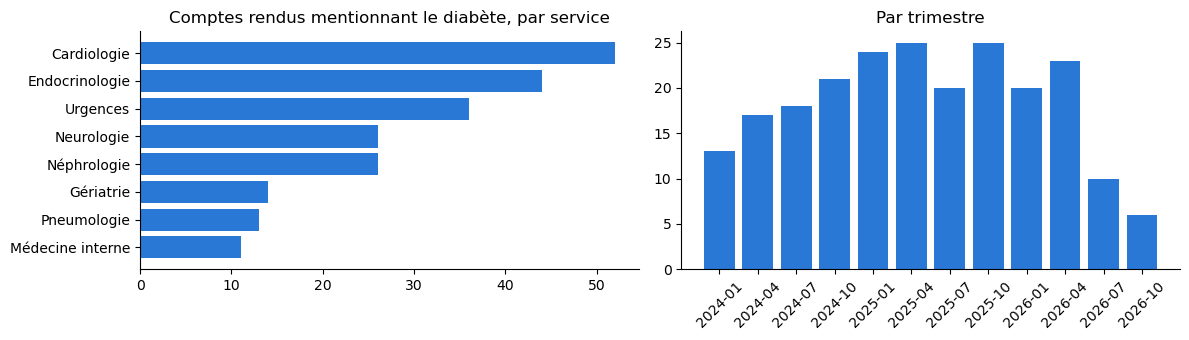

In [15]:
# Le même résultat en graphique
import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
s = {b["key"]: b["doc_count"] for b in aggs["par_service"]["buckets"]}
a1.barh(list(s)[::-1], list(s.values())[::-1], color="#2a78d6")
a1.set_title("Comptes rendus mentionnant le diabète, par service")
t = {b["key_as_string"][:7]: b["doc_count"] for b in aggs["par_trimestre"]["buckets"]}
a2.bar(list(t), list(t.values()), color="#2a78d6")
a2.set_title("Par trimestre"); a2.tick_params(axis="x", rotation=45)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Partie 04 · Pertinence et sens

### Le piège de la négation

La requête « diabète » trouve aussi « Pas de diabète connu », « Père diabétique » ou « Suspicion de diabète gestationnel ».
Regardez les extraits mis en surbrillance :

In [16]:
q = {"size": 600, "_source": ["contenu"],
     "query": {"match": {"contenu": "diabète"}},
     "highlight": {"fields": {"contenu": {"fragment_size": 60, "number_of_fragments": 1}},
                   "pre_tags": [">>"], "post_tags": ["<<"]}}
res = client.search(index=INDEX_FR, body=q)
trouves = res["hits"]["hits"]
print(len(trouves), "comptes rendus trouvés pour « diabète »\n")
for h in trouves[:12]:
    print(h["_id"], "…", h["highlight"]["contenu"][0], "…")

222 comptes rendus trouvés pour « diabète »

CR0456 … >>Diabète<< >>sucré<< de type 2 connu, suivi en ville. …
CR0473 … >>Diabète<< >>sucré<< de type 2 connu, suivi en ville. …
CR0257 … >>Diabète<< >>sucré<< de type 2 connu, suivi en ville. …
CR0495 … >>Diabète<< >>sucré<< de type 2 connu, suivi en ville. …
CR0051 … Antécédents : >>diabète<< >>sucré<< de type 2. …
CR0575 … Patiente connue pour un >>diabète<< >>sucré<< de type 2. …
CR0466 … Patient connu pour un >>diabète<< >>sucré<< de type 2. …
CR0279 … Aucun antécédent de >>diabète<< >>sucré<< de type 2. …
CR0001 … Patient connu pour un >>diabète<< >>sucré<< de type 2. …
CR0136 … >>Diabète<< >>sucré<< de type 2 connu, suivi en ville. …
CR0368 … >>Diabète<< >>sucré<< de type 2 connu, suivi en ville. …
CR0435 … Patient connu pour un >>diabète<< >>sucré<< de type 2. …


### Qualifier chaque mention avec EDS-NLP

Le pipeline de la slide « EDS-NLP » repère les mentions de diabète et dit si elles sont niées, familiales
ou hypothétiques. Appliquez-le au texte de chaque compte rendu trouvé, et classez le document :
- **affirmé** si au moins une mention n'est ni niée, ni familiale, ni hypothétique ;
- sinon, le statut de la première mention (nié, familial, hypothèse).

In [ ]:
#%pip install edsnlp

  Using cached edsnlp-0.24.0-cp311-cp311-win_amd64.whl.metadata (7.9 kB)
  Using cached loguru-0.8.0-py3-none-any.whl.metadata (23 kB)
  Using cached pysimstring-1.3.0-cp311-cp311-win_amd64.whl.metadata (954 bytes)
  Using cached regex-2026.11.19-cp311-cp311-win_amd64.whl.metadata (41 kB)
  Using cached spacy-3.8.18-cp311-cp311-win_amd64.whl.metadata (28 kB)
  Using cached confit-0.13.0-py3-none-any.whl.metadata (7.9 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached umls_downloader-0.1.4-py3-none-any.whl.metadata (17 kB)
  Using cached build-1.6.1-py3-none-any.whl.metadata (5.6 kB)
  Using cached xxhash-4.1.0-cp311-cp311-win_amd64.whl.metadata (19 kB)
  Using cached pyarrow-26.0.1-cp311-cp311-win_amd64.whl.metadata (3.0 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached pydantic-2.14.4-py3-none-any.whl.metadata (143 kB)
  Using cached pyproject_hooks-1.3.3-py3-none-any.whl.metadata (1.3 kB)
  Using cached catalogue-2.0.10-p

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

In [17]:
import edsnlp, edsnlp.pipes as eds
nlp = edsnlp.blank("eds")
nlp.add_pipe(eds.sentences())
nlp.add_pipe(eds.normalizer())
nlp.add_pipe(eds.matcher(terms={"diabete": ["diabète", "diabétique", "DT2", "diabète sucré"]}, attr="NORM"))
nlp.add_pipe(eds.negation())
nlp.add_pipe(eds.family())
nlp.add_pipe(eds.hypothesis())

doc = nlp("Pas de diabète connu. Père diabétique.")
for e in doc.ents:
    print(e.text, e._.negation, e._.family, e._.hypothesis)

2026-11-21 11:29:41.511 +01:00 | WARNING  | edsnlp.pipes.qualifiers.family.family:__init__:169 - You have requested that the pipeline use annotations provided by the `section` pipeline, but it was not set. Skipping that step.


diabète True False False
diabétique False True False


In [18]:
# À COMPLÉTER : le statut d'un texte
def statut(texte):
    doc = nlp(texte)
    mentions = []

    for e in doc.ents:
        if e._.negation:
            mentions.append("nié")
        elif e._.family:
            mentions.append("familial")
        elif e._.hypothesis:
            mentions.append("hypothèse")
        else:
            mentions.append("affirmé")

    if not mentions:
        return "aucune mention"

    return "affirmé" if "affirmé" in mentions else mentions[0]


statuts = pd.Series({
    h["_id"]: statut(h["_source"]["contenu"])
    for h in trouves
})
print(statuts.value_counts().to_string())

affirmé           153
nié                37
familial           15
hypothèse          14
aucune mention      3


**Questions** : sur les comptes rendus trouvés par « diabète », combien parlent vraiment d'un patient diabétique ?
Que contiennent les documents classés « aucune mention » ? (indice : les fautes de frappe et les synonymes que
le dictionnaire d'EDS-NLP ne connaît pas)

1. Sur les 222 comptes rendus trouvés, 153 contiennent au moins une mention affirmée de diabète chez le patient, selon EDS-NLP.
2. Les 3 comptes rendus classés « aucune mention » ont été trouvés par OpenSearch, mais EDS-NLP n’y a reconnu aucune mention. Cela peut s’expliquer par une faute de frappe ou une variante absente du dictionnaire utilisé.

### Enrichir l'index pour construire une cohorte (slide « Enrichir l'index »)

On écrit le statut dans un nouveau champ `keyword`, `diabete_statut`, puis on filtre dessus : la cohorte
« patients diabétiques » ne contient plus les négations ni les antécédents familiaux.

In [19]:
client.indices.put_mapping(index=INDEX_FR, body={"properties": {"diabete_statut": {"type": "keyword"}}})
helpers.bulk(client, ({"_op_type": "update", "_index": INDEX_FR, "_id": cid,
                       "doc": {"diabete_statut": s}} for cid, s in statuts.items()))
client.indices.refresh(index=INDEX_FR)

q = {"size": 0,
     "query": {"bool": {"must": [{"match": {"contenu": "diabète"}}],
                        "filter": [{"term": {"diabete_statut": "affirmé"}}]}},
     "aggs": {"patients": {"cardinality": {"field": "patient_id"}}}}
res = client.search(index=INDEX_FR, body=q)
print("Comptes rendus avec un diabète affirmé :", res["hits"]["total"]["value"])
print("Patients distincts :", res["aggregations"]["patients"]["value"])

Comptes rendus avec un diabète affirmé : 153
Patients distincts : 112


### Pour aller plus loin

- Ajoutez au dictionnaire d'EDS-NLP les fautes de frappe trouvées à l'étape 4 : combien de documents passent
  de « aucune mention » à un statut ?
- Refaites la négation pour l'insuffisance cardiaque (« Absence d'IC », « Aucun antécédent d'insuffisance cardiaque »).
- Dans Dashboards (http://localhost:5601), *Dev Tools* : retapez la requête de l'étape 3 en JSON.